# DSCI 552 — Homework 6


**Name:** Wendu Liu

**GitHub Username:** wenduliu-ops

**USC ID:**  8752-8093-81

**Reproducibility:** Python 3; set random seed 42. Keep the provided
Homework 6 Data.zip in the same directory as the notebook (or in an
upload/ subdirectory). Run cells from top to bottom. The XGBoost
cross-validation and full-data SMOTE stages may take several minutes.


## 1. Tree-Based Methods

**Packages.** If needed, run this command in a terminal before opening the
notebook: pip install numpy pandas scipy matplotlib seaborn scikit-learn
xgboost imbalanced-learn

The code below sets a reproducible random seed, limits the total CPU threads,
and defines a shared evaluation function. The original APS dataset is read
directly from the provided ZIP archive.


In [13]:
from pathlib import Path
from zipfile import ZipFile
import math
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
N_JOBS = min(4, os.cpu_count() or 2)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 15)
print(f"Using up to {N_JOBS} CPU threads; random_state={RANDOM_STATE}")


def evaluation_table(model, X_tr, y_tr, X_te, y_te, name, plot=True):
    """Report classification error, confusion matrices, and ROC/AUC."""
    results = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 4)) if plot else (None, None)
    for i, (label, X, y) in enumerate(
        [("train", X_tr, y_tr), ("test", X_te, y_te)]
    ):
        pred = model.predict(X)
        probability = model.predict_proba(X)[:, 1]
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        results.append({
            "model": name, "split": label,
            "misclassification": 1 - accuracy_score(y, pred),
            "AUC": roc_auc_score(y, probability),
            "TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "positive_recall": tp / (tp + fn),
            "specificity": tn / (tn + fp),
        })
        if plot:
            fpr, tpr, _ = roc_curve(y, probability)
            axes[0].plot(
                fpr, tpr,
                label=f"{label}: AUC={roc_auc_score(y, probability):.3f}"
            )
            ConfusionMatrixDisplay.from_predictions(
                y, pred, labels=[0, 1], display_labels=["neg", "pos"],
                ax=axes[1] if label == "test" else None,
                colorbar=False
            ) if label == "test" else None
    if plot:
        axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
        axes[0].set(xlabel="False positive rate", ylabel="True positive rate",
                    title=f"{name}: train and test ROC")
        axes[0].legend()
        axes[1].set_title(f"{name}: test confusion matrix")
        plt.tight_layout()
        plt.show()
    output = pd.DataFrame(results).set_index(["model", "split"])
    display(output.round(4))
    print("Confusion-matrix convention: rows=true labels, columns=predicted labels.")
    print("Train:", confusion_matrix(y_tr, model.predict(X_tr), labels=[0, 1]))
    print("Test: ", confusion_matrix(y_te, model.predict(X_te), labels=[0, 1]))
    return output


Using up to 4 CPU threads; random_state=42


### (a) Download the APS Failure data

The supplied ZIP already contains the original training (60,000 samples)
and test (16,000 samples) files, with 170 numeric predictors and a binary
target called class. The first several lines of each CSV contain dataset
description text, so they must be skipped before reading the header.


In [14]:
ZIP_CANDIDATES = [
    Path("Homework 6 Data.zip"),
    Path("upload/Homework 6 Data.zip"),
    Path("../Homework 6 Data.zip"),
    Path("../upload/Homework 6 Data.zip"),
]
zip_path = next((p for p in ZIP_CANDIDATES if p.exists()), None)
if zip_path is None:
    raise FileNotFoundError(
        "Place 'Homework 6 Data.zip' next to this notebook or inside 'upload/'."
    )

def read_aps_csv(zf, name):
    with zf.open(name) as file:
        header_line = next(
            i for i, line in enumerate(file) if line.startswith(b"class,")
        )
    with zf.open(name) as file:
        return pd.read_csv(
            file, skiprows=header_line, na_values=["na", "NA"],
            low_memory=False
        )

with ZipFile(zip_path) as archive:
    train_df = read_aps_csv(archive, "aps_failure_training_set.csv")
    test_df = read_aps_csv(archive, "aps_failure_test_set.csv")

y_train = train_df["class"].map({"neg": 0, "pos": 1}).astype("int8")
y_test = test_df["class"].map({"neg": 0, "pos": 1}).astype("int8")
X_train_raw = train_df.drop(columns="class").apply(
    pd.to_numeric, errors="coerce"
).astype("float32")
X_test_raw = test_df.drop(columns="class").apply(
    pd.to_numeric, errors="coerce"
).astype("float32")
assert X_train_raw.shape == (60000, 170)
assert X_test_raw.shape == (16000, 170)
assert list(X_train_raw.columns) == list(X_test_raw.columns)
assert not y_train.isna().any() and not y_test.isna().any()
print("Training:", X_train_raw.shape, "Testing:", X_test_raw.shape)
print("Missing training entries:", int(X_train_raw.isna().sum().sum()))
print("Missing test entries:", int(X_test_raw.isna().sum().sum()))

# This train-only imputation is for exploratory plots and the two RF fits.
# Grid searches below use fold-local imputers to prevent CV leakage.
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw), columns=X_train_raw.columns
).astype("float32")
X_test = pd.DataFrame(
    imputer.transform(X_test_raw), columns=X_test_raw.columns
).astype("float32")
assert not X_train.isna().any().any() and not X_test.isna().any().any()
display(train_df.head(3).iloc[:, :8])


Training: (60000, 170) Testing: (16000, 170)
Missing training entries: 850015
Missing test entries: 228680


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

**Answer (b)(i).** Missing data can be addressed by deletion of incomplete
observations, simple imputation (mean/median/most frequent), nearest-neighbor
imputation, iterative/model-based imputation, or methods that support missing
inputs natively. Deleting rows is inappropriate when a substantial fraction
has missing values. Median imputation is chosen here because it is robust to
outliers and cheap for a large numerical dataset.

Imputation is fitted **only on training data** and applied unchanged to the
held-out test data. When cross-validating XGBoost, the imputer is instead fit
separately inside every training fold. This prevents information from
validation or test observations leaking into the training procedure.

Source: [scikit-learn documentation: Imputation of missing values](https://scikit-learn.org/stable/modules/impute.html).


#### (ii) Calculate the coefficient of variation

In [15]:
means = X_train.mean(axis=0)
sample_sds = X_train.std(axis=0, ddof=1)
# CV = s / m; predictors have nonnegative means in this data.
# A zero mean gives an undefined coefficient and is marked NaN.
cv_features = sample_sds.div(means.replace(0, np.nan))
cv_features = cv_features.replace([np.inf, -np.inf], np.nan)
cv_table = pd.DataFrame({
    "mean": means, "sample_std": sample_sds, "CV": cv_features
}).sort_values("CV", ascending=False)
print("Coefficient of variation (top 20 of 170 features):")
display(cv_table.head(20).round(5))
print("Number with undefined CV (zero mean):", cv_features.isna().sum())


Coefficient of variation (top 20 of 170 features):


,mean,sample_std,CV
cf_000,143107.531250,3.504525e+07,244.887527
co_000,143330.031250,3.504525e+07,244.507355
ad_000,143438.296875,3.504525e+07,244.322815
cs_009,770.509705,1.833278e+05,237.930573
dh_000,4392.640625,5.412441e+05,123.216103
dj_000,37.271332,4.379167e+03,117.494232
ag_000,219.157745,2.036364e+04,92.917763
as_000,125.407898,1.095219e+04,87.332497
ay_009,1149.619629,9.741156e+04,84.733727
ak_000,907.660706,7.299859e+04,80.424980


Number with undefined CV (zero mean): 0


#### (iii) Plot a correlation matrix

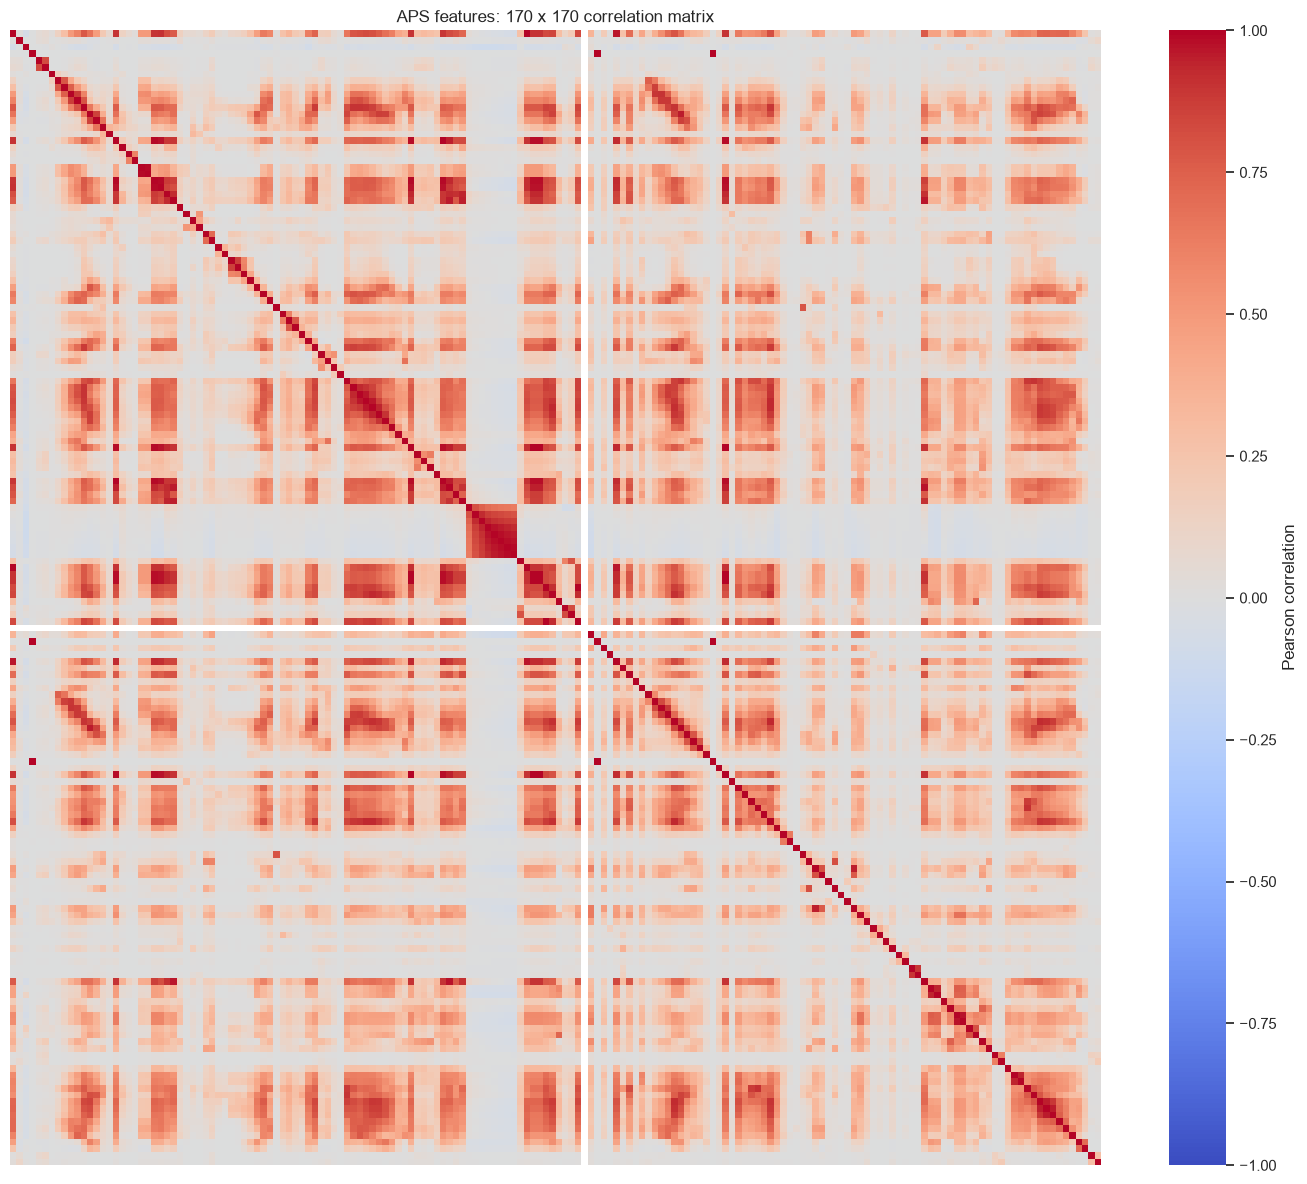

Pairs with high absolute correlation (|r| > 0.9) may be redundant.


In [16]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    xticklabels=False, yticklabels=False, ax=ax,
    cbar_kws={"label": "Pearson correlation"}
)
ax.set_title("APS features: 170 x 170 correlation matrix")
plt.tight_layout()
plt.show()
print("Pairs with high absolute correlation (|r| > 0.9) may be redundant.")


#### (iv) Scatter plots and box plots for highest-CV features

Use the **13** largest finite coefficients of variation, since
floor(sqrt(170)) = 13. A stratified scatterplot sample keeps the figure
readable, while the box plots include the entire training set. A log(1+x)
scale makes the heavily right-skewed APS measurements easier to compare.

**Interpretation:** High CV means substantial *relative dispersion*, not
necessarily relevance to the class. Visible class separation may indicate
predictive signal, but scatter plots alone do not establish statistical
significance, account for confounding, or demonstrate out-of-sample
prediction quality. We therefore retain all 170 features for modeling.


Top 13 features by CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


c:\Users\Liuwe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\plotting\_matplotlib\misc.py:99: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[j])
c:\Users\Liuwe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\plotting\_matplotlib\misc.py:100: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(boundaries_list[i])
c:\Users\Liuwe\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\plotting\_matplotlib\misc.py:90: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[i])


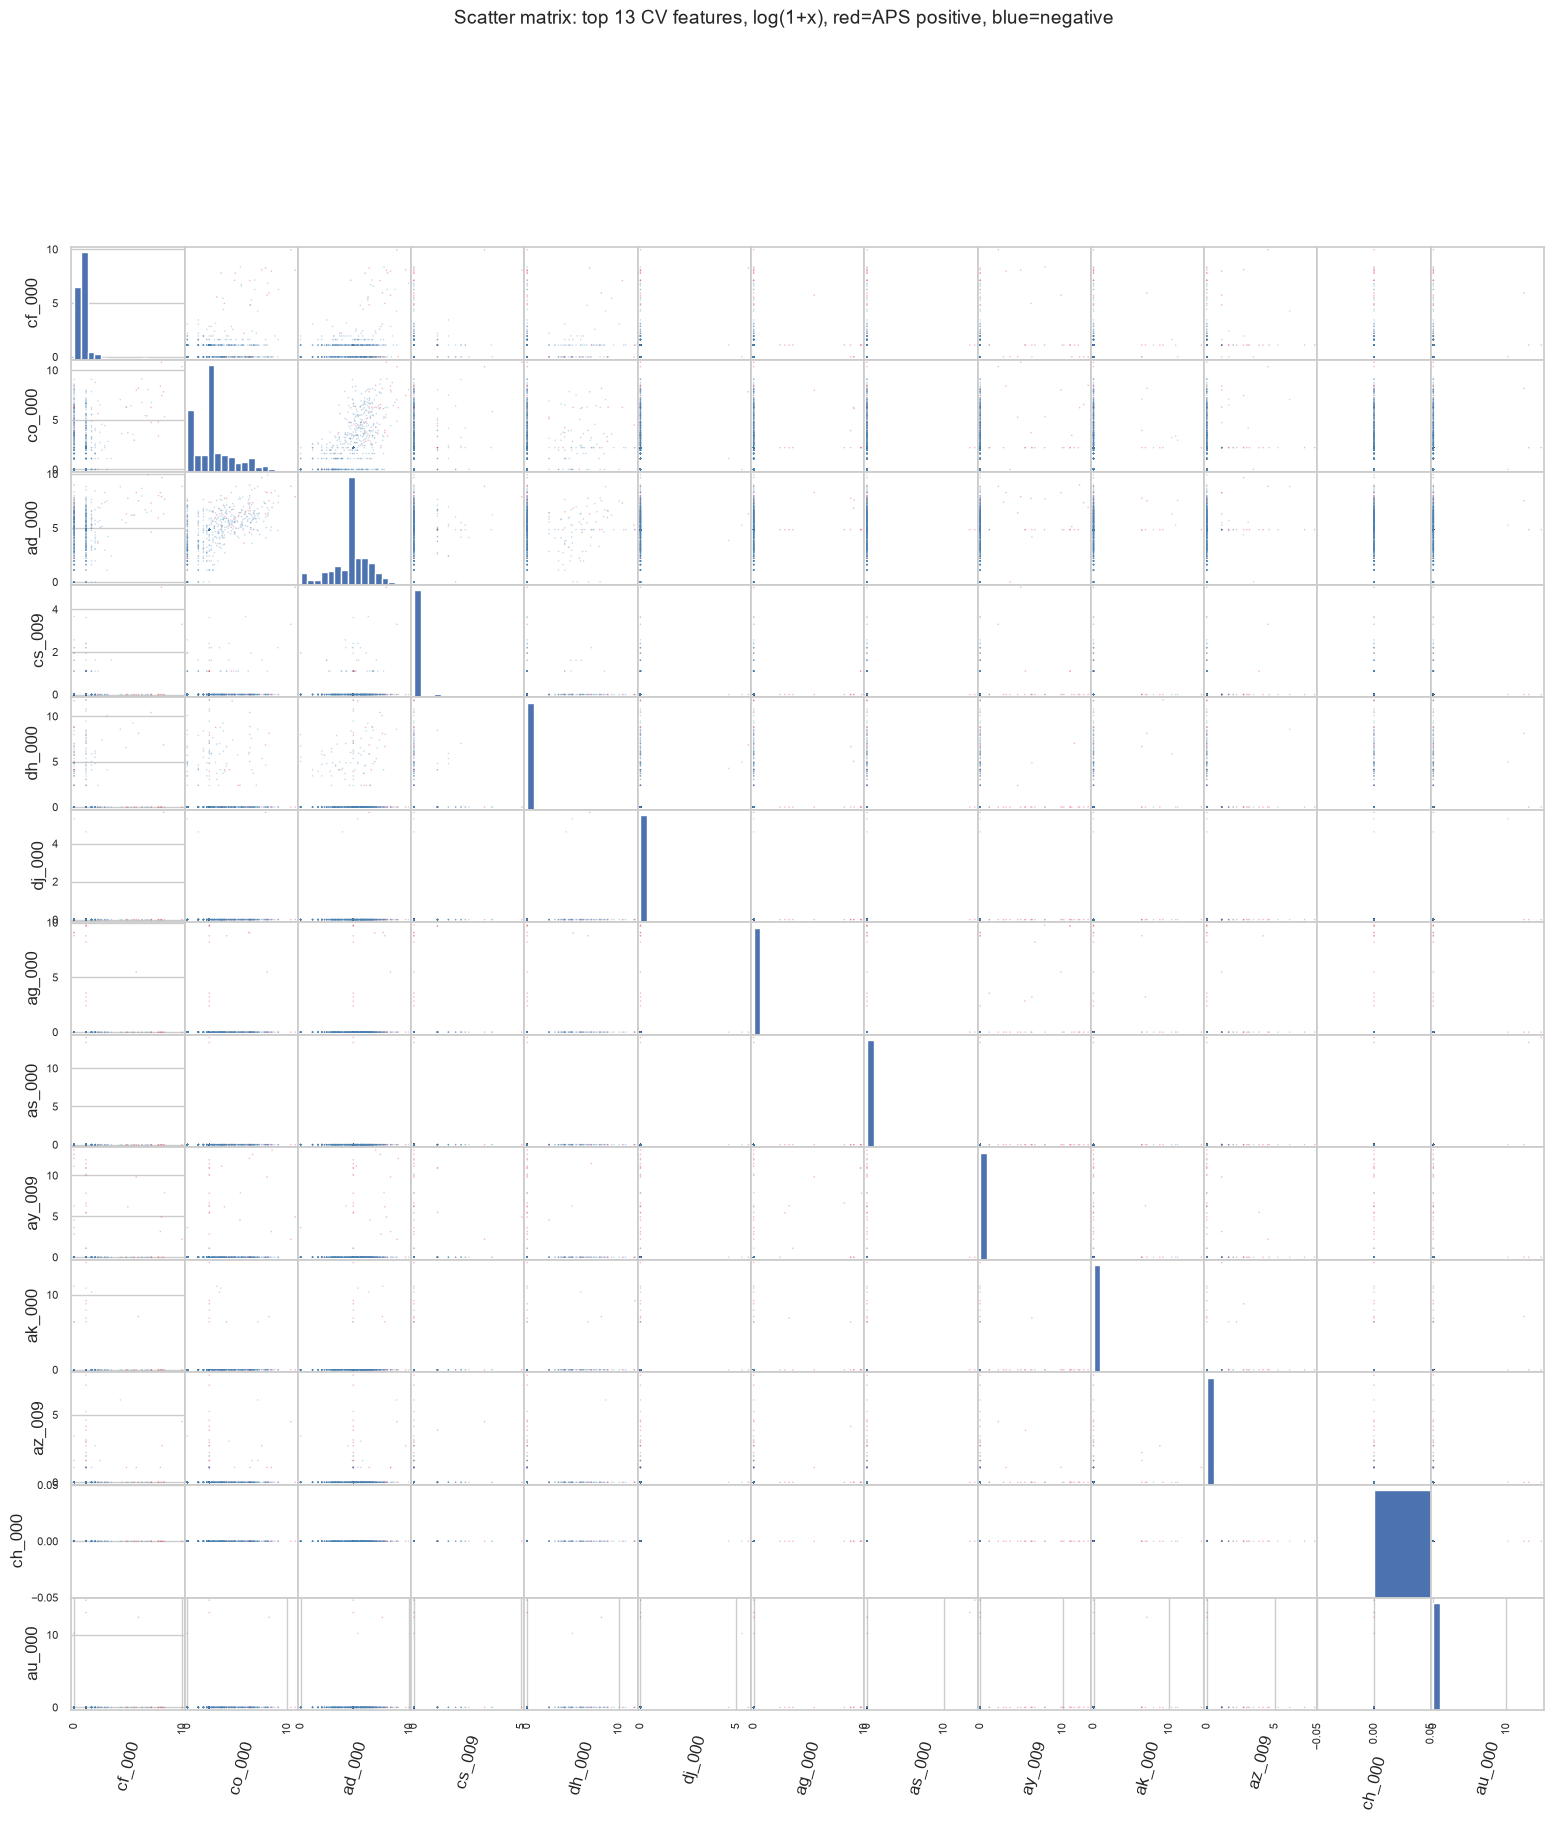

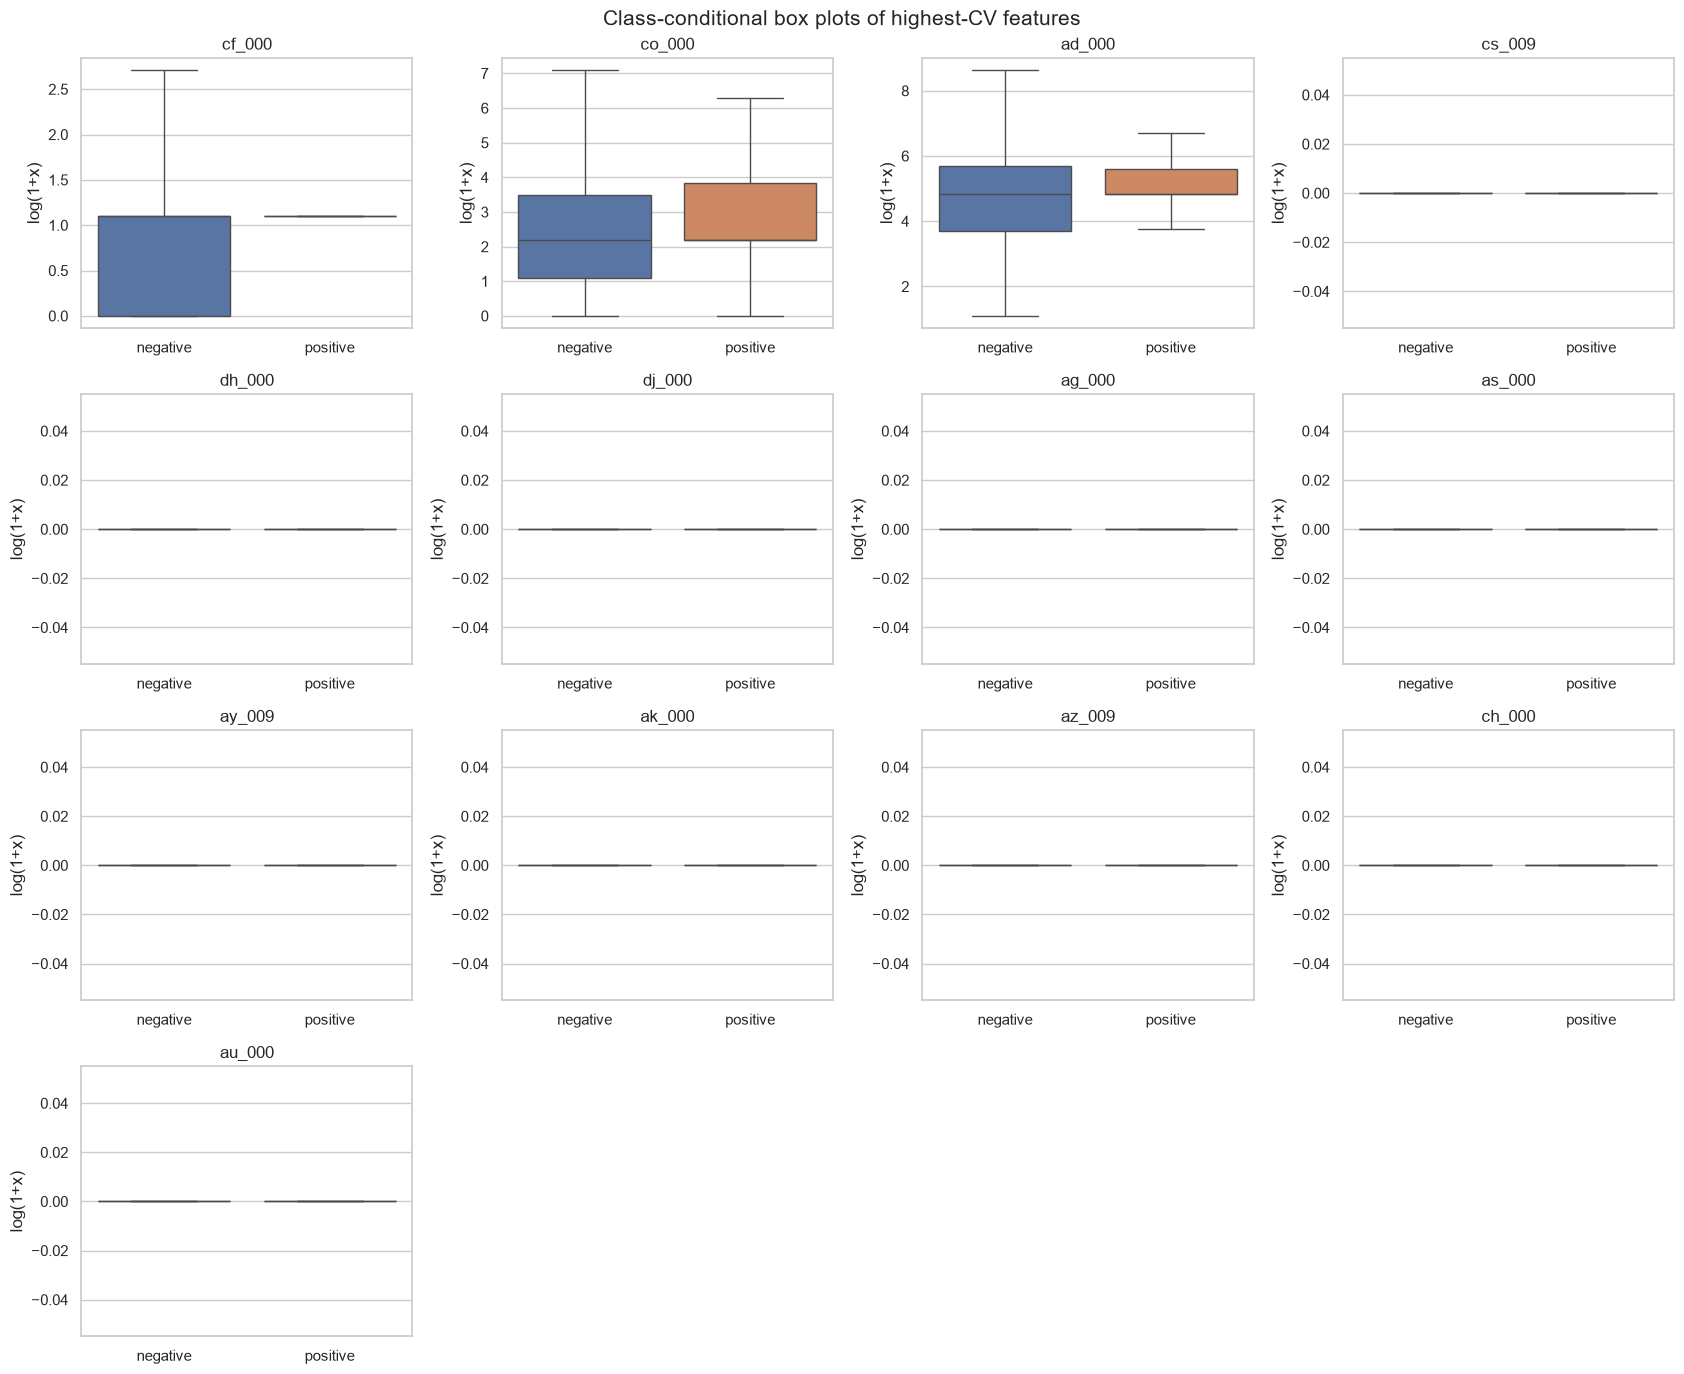

In [17]:
n_selected = math.isqrt(X_train.shape[1])  # floor(sqrt(170)) = 13
top_features = cv_features.dropna().nlargest(n_selected).index.tolist()
print("Top", n_selected, "features by CV:")
print(top_features)

# Stratified visualization sample: preserve enough positive observations.
pos_idx = y_train[y_train == 1].sample(n=120, random_state=42).index
neg_idx = y_train[y_train == 0].sample(n=700, random_state=42).index
draw_idx = np.r_[pos_idx, neg_idx]
visual_data = np.log1p(X_train.loc[draw_idx, top_features].clip(lower=0))
colors = np.where(y_train.loc[draw_idx].to_numpy() == 1, "crimson", "steelblue")

# Every one of the 13 selected features appears in this scatterplot matrix.
from pandas.plotting import scatter_matrix
axes = scatter_matrix(
    visual_data, figsize=(19, 19), diagonal="hist",
    color=colors, alpha=0.3, s=5, hist_kwds={"bins": 16}
)
for ax in axes[-1, :]:
    ax.set_xlabel(ax.get_xlabel(), rotation=75)
plt.suptitle(
    "Scatter matrix: top 13 CV features, log(1+x), "
    "red=APS positive, blue=negative",
    y=1.005, fontsize=14
)
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(17, 14))
for feature, ax in zip(top_features, axes.ravel()):
    sns.boxplot(
        x=y_train.map({0: "negative", 1: "positive"}),
        y=np.log1p(X_train[feature].clip(lower=0)),
        hue=y_train.map({0: "negative", 1: "positive"}),
        legend=False, showfliers=False, ax=ax
    )
    ax.set(title=feature, xlabel="", ylabel="log(1+x)")
for ax in axes.ravel()[len(top_features):]:
    ax.axis("off")
fig.suptitle("Class-conditional box plots of highest-CV features", fontsize=15)
plt.tight_layout()
plt.show()


#### (v) Is this data set imbalanced?

In [18]:
counts = y_train.map({0: "negative", 1: "positive"}).value_counts()
display(pd.DataFrame({
    "count": counts,
    "percent": (100 * counts / len(y_train)).round(3)
}))
print("Imbalance ratio (negative:positive):",
      f"{(y_train == 0).sum() / (y_train == 1).sum():.1f}:1")
print("Conclusion: the positive APS failure class is strongly underrepresented.")


,count,percent
class,,
negative,59000,98.333
positive,1000,1.667


Imbalance ratio (negative:positive): 59.0:1
Conclusion: the positive APS failure class is strongly underrepresented.


### (c) Random forest without imbalance compensation

Fit a standard bootstrap random forest with no class weights or resampling.
Report training/test confusion matrices, ROC curves, AUC, classification
error, and out-of-bag (OOB) error. OOB predictions come from trees whose
bootstrap samples excluded a given training observation.


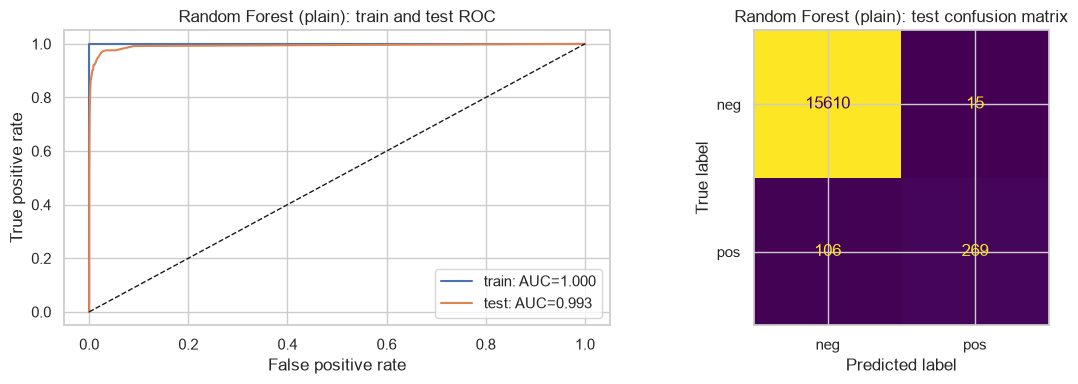

misclassification     AUC   TP  FP     TN   FN  \
model                 split                                                   
Random Forest (plain) train             0.0000  1.0000  999   0  59000    1   
                      test              0.0076  0.9927  269  15  15610  106   

                             positive_recall  specificity  
model                 split                                
Random Forest (plain) train           0.9990        1.000  
                      test            0.7173        0.999

Confusion-matrix convention: rows=true labels, columns=predicted labels.
Train: [[59000     0]
 [    1   999]]
Test:  [[15610    15]
 [  106   269]]
Plain RF OOB error: 0.00617
Plain RF test error: 0.00756
Absolute difference: 0.00140


In [19]:
rf_plain = RandomForestClassifier(
    n_estimators=100, max_features="sqrt", bootstrap=True,
    oob_score=True, class_weight=None,
    random_state=RANDOM_STATE, n_jobs=N_JOBS
)
rf_plain.fit(X_train, y_train)
rf_plain_results = evaluation_table(
    rf_plain, X_train, y_train, X_test, y_test,
    "Random Forest (plain)"
)
plain_oob_error = 1 - rf_plain.oob_score_
plain_test_error = rf_plain_results.loc[("Random Forest (plain)", "test"),
                                        "misclassification"]
print(f"Plain RF OOB error: {plain_oob_error:.5f}")
print(f"Plain RF test error: {plain_test_error:.5f}")
print(f"Absolute difference: {abs(plain_oob_error-plain_test_error):.5f}")


### (d) Random forest with imbalance compensation

A common strategy is to give the rare class a larger loss weight, sample
a balanced number of examples for each tree, or resample the training data.
Here, class_weight="balanced_subsample" makes each tree calculate
inverse-frequency class weights from its own bootstrap sample. Neither
validation nor test labels influence these weights. The models use the
same tree count and seed for a fair comparison.

Class weighting often improves positive-class recall, although it can
increase false positives. Overall misclassification alone may obscure this
trade-off because approximately 98.3% of observations are negative.

Source: [scikit-learn RandomForestClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).


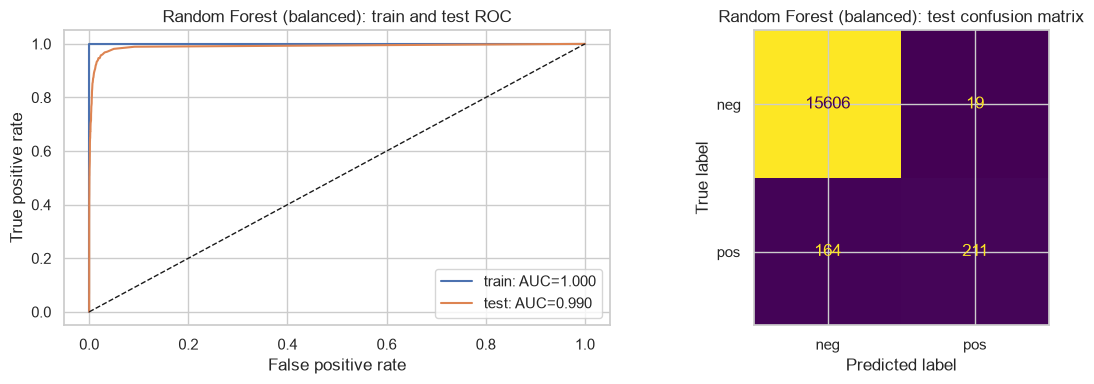

misclassification     AUC   TP  FP     TN  \
model                    split                                              
Random Forest (balanced) train             0.0000  1.0000  999   0  59000   
                         test              0.0114  0.9904  211  19  15606   

                                 FN  positive_recall  specificity  
model                    split                                     
Random Forest (balanced) train    1           0.9990       1.0000  
                         test   164           0.5627       0.9988

Confusion-matrix convention: rows=true labels, columns=predicted labels.
Train: [[59000     0]
 [    1   999]]
Test:  [[15606    19]
 [  164   211]]
Balanced RF OOB error: 0.00802
Balanced RF test error: 0.01144


,misclassification,AUC,positive_recall,specificity,FP,FN
model,,,,,,
Random Forest (plain),0.0076,0.9927,0.7173,0.9990,15,106
Random Forest (balanced),0.0114,0.9904,0.5627,0.9988,19,164


Interpretation: prioritize the change in minority-class recall and FN count, as well as AUC; class weighting does not guarantee a better AUC.


In [20]:
rf_balanced = RandomForestClassifier(
    n_estimators=100, max_features="sqrt", bootstrap=True,
    oob_score=True, class_weight="balanced_subsample",
    random_state=RANDOM_STATE, n_jobs=N_JOBS
)
rf_balanced.fit(X_train, y_train)
rf_balanced_results = evaluation_table(
    rf_balanced, X_train, y_train, X_test, y_test,
    "Random Forest (balanced)"
)
balanced_oob_error = 1 - rf_balanced.oob_score_
print(f"Balanced RF OOB error: {balanced_oob_error:.5f}")
print(f"Balanced RF test error: "
      f"{rf_balanced_results.loc[('Random Forest (balanced)', 'test'), 'misclassification']:.5f}")
display(
    pd.concat([rf_plain_results, rf_balanced_results])
    .xs("test", level="split")
    [["misclassification", "AUC", "positive_recall", "specificity", "FP", "FN"]]
    .round(4)
)
print("Interpretation: prioritize the change in minority-class recall and FN "
      "count, as well as AUC; class weighting does not guarantee a better AUC.")


### (e) L1-regularized XGBoost, without class compensation

**Implementation note about the wording of the assignment:** The standard
XGBoost tree booster (gbtree) fits numerical leaf weights, **not** an
independent L1-penalized logistic-regression model at every node. The
closest standard XGBoost classifier uses binary logistic loss and
reg_alpha to impose an L1 penalty on leaf weights. The code implements
this reproducible standard API and does not claim that it is literally
a model tree with linear/logistic leaves.

We select alpha from {0, 0.1, 1, 10} using stratified five-fold CV
(ROC AUC as the selection score). The CV misclassification shown below
is 1 minus the corresponding mean CV accuracy for the selected alpha.
This is not a fully nested unbiased estimate because alpha selection
and reported CV metrics use the same folds; the test set remains untouched
until final reporting.

Source: [XGBoost official parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).


,param_model__reg_alpha,mean_test_AUC,std_test_AUC,mean_test_accuracy,rank_test_AUC
2,1.0,0.9897,0.0041,0.9932,1
1,0.1,0.9887,0.0043,0.9930,2
0,0.0,0.9881,0.0045,0.9931,3
3,10.0,0.9880,0.0042,0.9922,4


Selected alpha=1, 5-fold CV AUC=0.9897, CV misclassification=0.0068


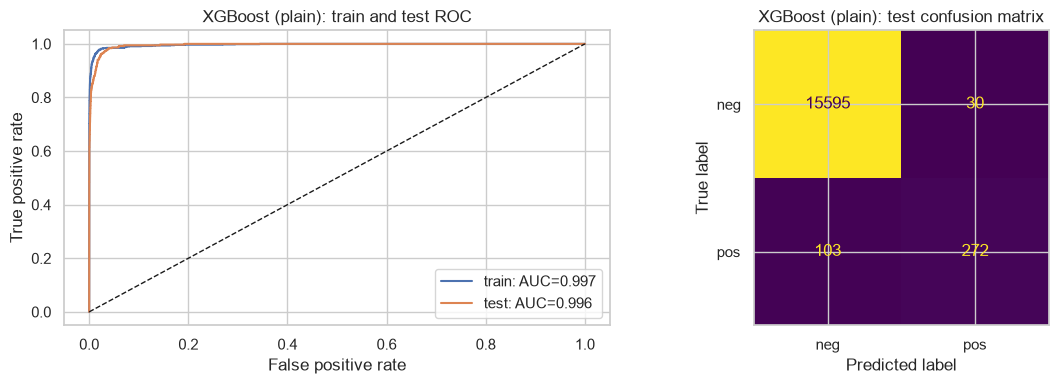

misclassification     AUC   TP  FP     TN   FN  \
model           split                                                   
XGBoost (plain) train             0.0042  0.9966  805  58  58942  195   
                test              0.0083  0.9956  272  30  15595  103   

                       positive_recall  specificity  
model           split                                
XGBoost (plain) train           0.8050       0.9990  
                test            0.7253       0.9981

Confusion-matrix convention: rows=true labels, columns=predicted labels.
Train: [[58942    58]
 [  195   805]]
Test:  [[15595    30]
 [  103   272]]
CV error vs held-out test error: 0.00677 0.00831


In [21]:
def make_xgb():
    return XGBClassifier(
        objective="binary:logistic", booster="gbtree",
        n_estimators=70, max_depth=4, learning_rate=0.10,
        subsample=0.85, colsample_bytree=0.85,
        tree_method="hist", reg_lambda=1.0, reg_alpha=0.0,
        eval_metric="logloss", random_state=RANDOM_STATE,
        n_jobs=N_JOBS
    )

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("model", make_xgb())
])
alpha_grid = {"model__reg_alpha": [0.0, 0.1, 1.0, 10.0]}
xgb_search = GridSearchCV(
    xgb_pipeline, alpha_grid,
    scoring={"AUC": "roc_auc", "accuracy": "accuracy"},
    refit="AUC", cv=CV, n_jobs=1, return_train_score=False
)
xgb_search.fit(X_train_raw, y_train)
xgb_cv_table = pd.DataFrame(xgb_search.cv_results_)[[
    "param_model__reg_alpha", "mean_test_AUC", "std_test_AUC",
    "mean_test_accuracy", "rank_test_AUC"
]].sort_values("rank_test_AUC")
display(xgb_cv_table.round(4))
xgb_alpha = xgb_search.best_params_["model__reg_alpha"]
xgb_cv_auc = xgb_search.cv_results_["mean_test_AUC"][xgb_search.best_index_]
xgb_cv_error = 1 - xgb_search.cv_results_["mean_test_accuracy"][xgb_search.best_index_]
print(f"Selected alpha={xgb_alpha:g}, 5-fold CV AUC={xgb_cv_auc:.4f}, "
      f"CV misclassification={xgb_cv_error:.4f}")
xgb_results = evaluation_table(
    xgb_search.best_estimator_,
    X_train_raw, y_train, X_test_raw, y_test,
    "XGBoost (plain)"
)
print("CV error vs held-out test error:",
      round(xgb_cv_error, 5),
      round(xgb_results.loc[("XGBoost (plain)", "test"), "misclassification"], 5))


### (f) Apply SMOTE and repeat the XGBoost analysis

SMOTE synthesizes minority-class examples based on training-set neighbors.
To avoid leakage, the order *inside each CV fold* is:

1. Fit the median imputer on the fold's training subset.
2. Impute the fold's training subset, then apply SMOTE **only to it**.
3. Fit XGBoost on the resulting balanced training fold.
4. Transform the untouched validation fold using that fold's imputer;
   **do not resample** validation or test observations.

imblearn.pipeline.Pipeline performs this sequence correctly. The full
60,000-row training data are used (no majority-class downsampling).
After choosing alpha, refitting the pipeline applies SMOTE to the full
training set. Test data are not resampled.

Source: [imbalanced-learn: common pitfalls and leakage](https://imbalanced-learn.org/stable/common_pitfalls.html).


,param_model__reg_alpha,mean_test_AUC,std_test_AUC,mean_test_accuracy,rank_test_AUC
0,0.0,0.9844,0.0060,0.9806,1
3,10.0,0.9843,0.0064,0.9796,2
2,1.0,0.9841,0.0064,0.9803,3
1,0.1,0.9833,0.0065,0.9804,4


Selected SMOTE alpha=0, 5-fold CV AUC=0.9844, CV error=0.0194


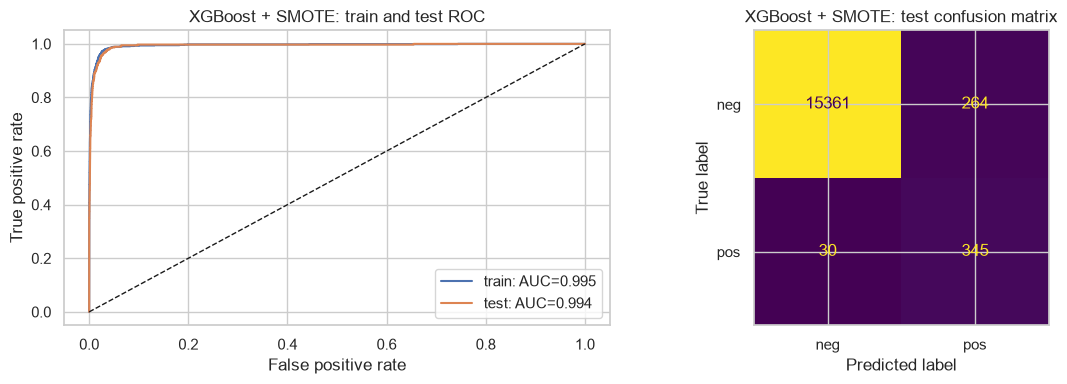

misclassification     AUC   TP    FP     TN  FN  \
model           split                                                    
XGBoost + SMOTE train             0.0184  0.9946  944  1047  57953  56   
                test              0.0184  0.9936  345   264  15361  30   

                       positive_recall  specificity  
model           split                                
XGBoost + SMOTE train            0.944       0.9823  
                test             0.920       0.9831

Confusion-matrix convention: rows=true labels, columns=predicted labels.
Train: [[57953  1047]
 [   56   944]]
Test:  [[15361   264]
 [   30   345]]
CV error vs held-out test error: 0.01937 0.01838
Held-out test comparison:


,misclassification,AUC,positive_recall,specificity,FP,FN
model,,,,,,
Random Forest (plain),0.0076,0.9927,0.7173,0.9990,15,106
Random Forest (balanced),0.0114,0.9904,0.5627,0.9988,19,164
XGBoost (plain),0.0083,0.9956,0.7253,0.9981,30,103
XGBoost + SMOTE,0.0184,0.9936,0.9200,0.9831,264,30


Interpretation: SMOTE can reduce the number of missed APS failures (FN), but may increase false alarms (FP). Evaluate both error types, not just overall accuracy.


In [22]:
xgb_smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("model", make_xgb())
])
smote_search = GridSearchCV(
    xgb_smote_pipeline, alpha_grid,
    scoring={"AUC": "roc_auc", "accuracy": "accuracy"},
    refit="AUC", cv=CV, n_jobs=1, return_train_score=False
)
smote_search.fit(X_train_raw, y_train)
smote_cv_table = pd.DataFrame(smote_search.cv_results_)[[
    "param_model__reg_alpha", "mean_test_AUC", "std_test_AUC",
    "mean_test_accuracy", "rank_test_AUC"
]].sort_values("rank_test_AUC")
display(smote_cv_table.round(4))
smote_alpha = smote_search.best_params_["model__reg_alpha"]
smote_cv_auc = smote_search.cv_results_["mean_test_AUC"][smote_search.best_index_]
smote_cv_error = 1 - smote_search.cv_results_["mean_test_accuracy"][smote_search.best_index_]
print(f"Selected SMOTE alpha={smote_alpha:g}, "
      f"5-fold CV AUC={smote_cv_auc:.4f}, CV error={smote_cv_error:.4f}")
smote_results = evaluation_table(
    smote_search.best_estimator_,
    X_train_raw, y_train, X_test_raw, y_test,
    "XGBoost + SMOTE"
)
print("CV error vs held-out test error:",
      round(smote_cv_error, 5),
      round(smote_results.loc[("XGBoost + SMOTE", "test"), "misclassification"], 5))

final_test_comparison = pd.concat([
    rf_plain_results, rf_balanced_results, xgb_results, smote_results
]).xs("test", level="split")
print("Held-out test comparison:")
display(final_test_comparison[[
    "misclassification", "AUC", "positive_recall",
    "specificity", "FP", "FN"
]].round(4))
print("Interpretation: SMOTE can reduce the number of missed APS failures "
      "(FN), but may increase false alarms (FP). Evaluate both error "
      "types, not just overall accuracy.")


## 2. ISLR 6.6.3 — Lasso constraint and the bias–variance tradeoff

Minimize the training residual sum of squares subject to

$$\sum_{j=1}^{p}|\beta_j|\leq s.$$

The constraint becomes less restrictive as s increases.


**(a) Training RSS — iv. Steadily decrease.** Increasing s enlarges the
feasible coefficient set. The minimum training RSS therefore cannot
increase; it decreases (or stays flat) until the unrestricted least-squares
solution is attainable.

**(b) Test RSS — ii. Decrease initially, then eventually increase (U-shaped).**
Small s usually underfits; relaxing the constraint can improve prediction,
but very large s may increase variance and overfit. This is the usual
expected test-error pattern, not a mathematical guarantee for every sample.

**(c) Variance — iii. Steadily increase.** A less constrained fit is
generally more sensitive to fluctuations in the training data.

**(d) Squared bias — iv. Steadily decrease.** Relaxing the constraint
allows a more flexible model and typically reduces systematic error.

**(e) Irreducible error — v. Remain constant.** The noise in the
data-generating process does not depend on s.

| Part | Correct choice |
|:---|:---|
| (a) Training RSS | **iv** |
| (b) Test RSS | **ii** |
| (c) Variance | **iii** |
| (d) Squared bias | **iv** |
| (e) Irreducible error | **v** |


## 3. ISLR 6.6.5 — Ridge and lasso for identical predictors


### (a) Ridge Regression Optimization Problem

The ridge regression optimization problem is

$$
\min_{\beta_1,\beta_2}\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2+\lambda(\beta_1^2+\beta_2^2).
$$

Since the two predictors are identical, let $x_{11}=x_{12}=x$ and $x_{21}=x_{22}=-x$. Also, let $y_1=y$ and $y_2=-y$. The optimization problem becomes

$$
\min_{\beta_1,\beta_2}2[y-x(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).
$$

### (b) Ridge Coefficients

The ridge coefficient estimates satisfy $\hat{\beta}_1=\hat{\beta}_2$ because the two predictors are identical and contribute equally to the model.

Taking the partial derivatives of the objective function gives

$$
-4x[y-x(\beta_1+\beta_2)]+2\lambda\beta_1=0
$$

and

$$
-4x[y-x(\beta_1+\beta_2)]+2\lambda\beta_2=0.
$$

Subtracting these equations gives

$$
2\lambda(\beta_1-\beta_2)=0.
$$

Since $\lambda>0$, we obtain

$$
\boxed{\hat{\beta}_1=\hat{\beta}_2}.
$$

Therefore, ridge regression assigns equal coefficients to these identical predictors.

### (c) Lasso Regression Optimization Problem

The lasso regression optimization problem is

$$
\min_{\beta_1,\beta_2}\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2+\lambda(|\beta_1|+|\beta_2|).
$$

Using the same assumptions from part (a), the optimization problem becomes

$$
\min_{\beta_1,\beta_2}2[y-x(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).
$$

### (d) Non-Unique Lasso Coefficients

Unlike ridge regression, lasso regression can produce multiple optimal solutions when the predictors are identical.

The residual sum of squares depends only on the sum $\beta_1+\beta_2$, rather than on the individual coefficients. Let $t=\beta_1+\beta_2$. For a fixed value of $t$, the smallest possible L1 penalty is $|t|$, because

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|t|.
$$

Equality holds when the two coefficients have the same sign or when one coefficient is zero.

Therefore, if the optimal sum $\hat{t}$ is nonzero, all coefficient pairs satisfying

$$
\boxed{\hat{\beta}_1=c\hat{t},\qquad\hat{\beta}_2=(1-c)\hat{t},\quad 0\leq c\leq1}
$$

produce the same minimum objective value.

For example, the optimal sum can be divided equally between the predictors or assigned entirely to one predictor. Both choices produce the same fitted values and the same L1 penalty.

As a result, there are infinitely many optimal lasso coefficient pairs when $\hat{t}\neq0$. However, if the penalty is sufficiently large that $\hat{t}=0$, the unique optimal pair is $(0,0)$. This demonstrates why lasso can select different coefficients for highly correlated predictors, whereas ridge tends to assign them similar values.

## 4. ISLR 8.4.5 — Bagged-tree probability averaging versus majority vote


The ten estimated probabilities of Red are
0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75.

**Majority vote:** Six trees assign Red (probability greater than 0.5)
and four assign Green. Therefore the final classification is **Red**.

**Average probability:** The sum is 4.50, so the average probability
of Red is \(4.50/10=0.45\). Because 0.45 is less than 0.5,
the final classification is **Green**.

These methods differ because majority voting treats all ten individual
class decisions equally, whereas averaging incorporates the strength of
each probability estimate.


## 5. ISLR 9.7.3 — Maximal-margin classifier in two dimensions

Observations:

| Observation | X₁ | X₂ | Class |
|---:|---:|---:|:---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |


**(a) Sketch:** The first plot below displays all seven labeled points.

**(b) Maximal-margin hyperplane:** The optimal separating line is
\(\boxed{x_2=x_1-\tfrac12}\), or
\(-2x_1+2x_2+1=0\).
It is halfway between the parallel closest class boundaries
\(x_2=x_1\) (Red) and \(x_2=x_1-1\) (Blue).

**(c) Classification rule:**
Classify Red if \(1-2X_1+2X_2>0\), Blue otherwise.
Thus \(\beta_0=1,\ \beta_1=-2,\ \beta_2=2\).

**(d) Margin:** The two dotted boundaries are
\(x_2=x_1\) and \(x_2=x_1-1\). The perpendicular distance from
the decision line to either boundary is \(1/(2\sqrt2)\);
the full margin width is \(1/\sqrt2\).

**(e) Support vectors:** Observations **2, 3, 5 and 6** lie on
the two margin boundaries.

**(f) Observation 7:** Point 7 at (4,1) lies well beyond the Blue margin,
so a small movement that leaves it outside the margin does not alter
the optimal hyperplane. The fit is determined by the support vectors.

**(g) Another, nonoptimal separator:** \(x_2=x_1-\tfrac14\).
It correctly separates all observations, but places the dividing line
closer to Red points and has a smaller minimum distance to training points.

**(h) No longer separable:** Add a **Blue** observation at (3,3.5).
This point is inside the convex hull of the Red observations, so no
straight line can place all Red points on one side and all Blue points
on the other. The second plot illustrates this example.


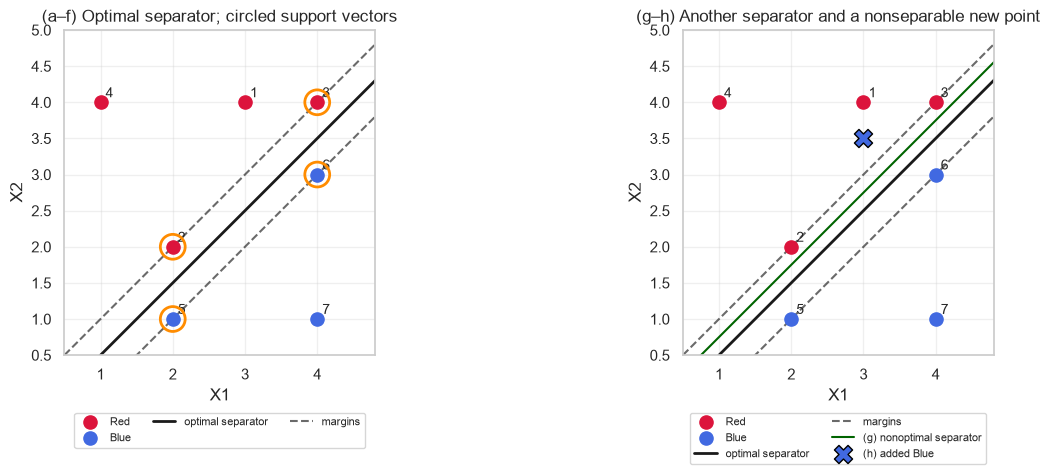

In [23]:
from matplotlib.lines import Line2D

toy = pd.DataFrame({
    "id": list(range(1, 8)),
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "class": ["Red"] * 4 + ["Blue"] * 3
})
support = {2, 3, 5, 6}
line_x = np.linspace(0.5, 5, 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax in axes:
    for label, color in [("Red", "crimson"), ("Blue", "royalblue")]:
        pts = toy[toy["class"] == label]
        ax.scatter(pts["X1"], pts["X2"], c=color, s=90, label=label, zorder=4)
    for row in toy.itertuples(index=False):
        ax.annotate(str(row.id), (row.X1 + 0.07, row.X2 + 0.07),
                    fontsize=10)
    ax.plot(line_x, line_x - 0.5, "k-", lw=2, label="optimal separator")
    ax.plot(line_x, line_x, "k--", alpha=0.65, label="margins")
    ax.plot(line_x, line_x - 1, "k--", alpha=0.65)
    ax.set(xlim=(0.5, 4.8), ylim=(0.5, 5), xlabel="X1", ylabel="X2")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
axes[0].set_title("(a–f) Optimal separator; circled support vectors")
for row in toy[toy["id"].isin(support)].itertuples(index=False):
    axes[0].scatter(row.X1, row.X2, s=320, facecolors="none",
                    edgecolors="darkorange", linewidths=2, zorder=5)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8)

axes[1].plot(line_x, line_x - 0.25, color="darkgreen", lw=1.5,
             label="(g) nonoptimal separator")
axes[1].scatter(3, 3.5, marker="X", s=170, c="royalblue",
                edgecolors="black", label="(h) added Blue")
axes[1].set_title("(g–h) Another separator and a nonseparable new point")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=8)
plt.tight_layout()
plt.show()
